# SLU02 - Subsetting data in pandas: Exercise notebook

In this notebook you'll practice the concepts you've learned in the learning and examples notebooks:

    - Setting pandas Dataframe index
    - Selecting columns with brackets notation
    - Selecting columns with dot notation
    - Selecting rows with loc 
    - Selecting rows with iloc
    - Multi-axis indexing
    - Masks
    - Subsetting on conditions
    - Removing and adding columns

In each exercise, you'll be asked to implement a function.

Let's dive right in.

In [20]:
import pandas as pd
import numpy as np
import math
import hashlib
import json
from utils import draw_base_puzzle, draw_final_puzzle

As you can seee, it's a pretty simple one. You will be given 10 clues to fill each of the columns and extract the horizontal words in blue. 

## Kaggle Competition

As an aspiring data scientist you are eager to apply your new skills and you decide to participate in a Kaggle competition. However, this competition has a twist: you must prove to have the minimum skills to enter it by completing a first data science based challenge. Easy, right?

<img src="media/kaggle_in_kaggle.png" alt="kaggle_in_kaggle" width="40%"/>

So you dive right into it. The assignment is the following: you must successfully complete a crossword puzzle where a set of hints requires you to extract information from the provided dataset. After completing all the words, you'll see the secret keyphrase (marked in blue) that will unlock the competition for you.

Load the puzzle below.

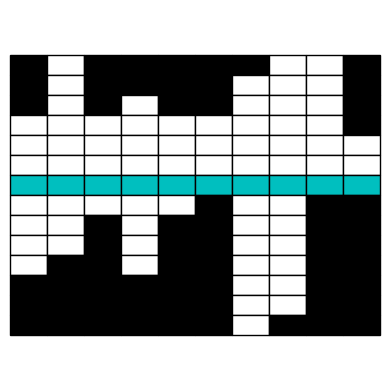

In [25]:
draw_base_puzzle()

But before that, start by loading the dataset from which you will extract the clues for the puzzle. It's the San Francisco Plant Finder dataset containing plant species suitable for planting in the SF area.

In [26]:
df = pd.read_csv('data/San_Francisco_Plant_Finder_Data.csv').convert_dtypes()
df.head()

,Latin_Name,Common_Name,Family_Name,Plant_Type,Bloom_Time,Flower_Color,Size_at_Maturity,Climate_Appropriate_Plants,Plant_Communities,Suitable_Site_Conditions,Soil_Type,Pruning_Needs,Water_Needs,Habitat_Value,Associated_Wildlife,Stormwater_Benefit,Stormwater_int,Appropriate_Location,Additional_Characteristices_Notes
0,Acacia baileyana 'Purpurea',Purple-leaf Acacia,Fabaceae,Tree (evergreen),Spring,Yellow,8.0,Exotic,<NA>,Sun,<NA>,<NA>,Low,<NA>,Birds;Butterflies,No,0,Sidewalk,"Fast grower, high maintenance."
1,Acer buergeranum,Trident Maple,Sapindaceae Aceraceae,Tree (deciduous),Spring,<NA>,6.0,Exotic,<NA>,"Sun,Part shade",<NA>,<NA>,Low,<NA>,<NA>,No,0,Sidewalk,"Prefers heat, wind protection."
2,Acer macrophyllum,Bigleaf Maple,Sapindaceae,Tree (deciduous),Spring,"Orange,Red,Yellow",8.0,CA Native,Riparian,"Sun,Shade","Clay,Loam,Sand,Rock",<NA>,Moderate,"Nesting,Pollinator",Bees;Birds;Butterflies,Yes,1,Garden,Provides shelter for wildlife
3,Acer negundo,Box Elder,Sapindaceae,Tree (deciduous),Spring,Pink,8.0,SF Native,"Chaparral,Grassland/prairie,Riparian,Woodland","Sun,Shade","Clay,Loam,Sand,Rock",<NA>,Moderate,"Buds/greens,Nesting",Bees;Birds;Butterflies;Insects,No,0,Garden,Withstands wind.
4,Acer rubrum,Red Maple,Sapindaceae,Tree (deciduous),Spring,Red,8.0,Exotic,<NA>,"Sun,Part shade","Clay,Loam,Sand",<NA>,Moderate,<NA>,<NA>,Yes,1,Sidewalk,"Prefers heat, wind protection"


Note that you should use this original dataset as input in every exercise.

Now let's dive into the clues! 

### Clue 1 - Highest value in plant communities

The first clue asks for the highest value of the column `Plant_Communities`, so we need to sort 
the dataframe by this column in descending order (using its natural order) and get the first value. 

To solve this, implement a function to change the index to the desired column and sort it in descending order.

Keep in mind that we don't want to discard the original index (which automatically got the name `index`) as it may be useful in the long run.

In [36]:
def change_and_sort_index(df, column):
    """ 
    Change the dataframe index to the desired column avoiding repeated columns.
    Then sort the index in descending order.
    
    Args:
        df (pd.DataFrame): the input DataFrame
        column: column name to use as index

    Returns:p
        (pd.DataFrame): resulting Dataframe

    """
    
    # YOUR CODE HERE
    df = df.reset_index()
    df = df.set_index(column)
    df = df.sort_index(ascending=False)
    return df

In [37]:
plant_dataset = pd.read_csv('data/San_Francisco_Plant_Finder_Data.csv').convert_dtypes()
new_dataset = change_and_sort_index(plant_dataset, "Plant_Communities")

assert isinstance(new_dataset, pd.DataFrame), 'The function should return a dataframe.'
assert new_dataset.shape == plant_dataset.shape, 'The shape of the resulting dataset is not correct.'
assert new_dataset.index.name == "Plant_Communities", 'The index column is not set correctly.'
assert hashlib.sha256(json.dumps(list(new_dataset.Latin_Name.array)).encode()).hexdigest() == \
'5ac16a83d0457892cd4d06da41359279da700498564cb845eb170b049a28d552'
, 'The dataset is not sorted correctly.'
assert 'index' in list(new_dataset.columns), 'Did you remove the old index?'
print('Well done!')

AssertionError: 

You can now use the function you built to get the first clue:

In [30]:
clue_dataset = change_and_sort_index(plant_dataset, "Plant_Communities")

first_clue = clue_dataset.index[0]

first_clue

AttributeError: 'NoneType' object has no attribute 'index'

### Clue 2 - Top habitat value for plants blooming in spring and summer

You now want to find the most common `Habitat_Value` for the subset of our data where the `Bloom_Time` equals `Spring,Summer`. To do this, you need a function to select rows by index values. 

Implement this function to select rows by index values below.

In [31]:
def select_rows_from_index(df, ids):
    """ 
    Select the desired rows from the given dataframe
    by the given index values.
    
    Args:
        df (pd.DataFrame): the input DataFrame
        ids: list with the desired index values to retrieve

    Returns:
        (pd.DataFrame): subsetted Dataframe

    """    
    
    # YOUR CODE HERE
    return df.loc[ids]

In [32]:
plant_dataset = pd.read_csv('data/San_Francisco_Plant_Finder_Data.csv').convert_dtypes()
indexed_dataset = change_and_sort_index(plant_dataset, "Bloom_Time")
desired_bloom_time = ['Winter', 'Summer,Fall']
filtered_dataset = select_rows_from_index(indexed_dataset, desired_bloom_time)

assert isinstance(filtered_dataset, pd.DataFrame), 'The function should return a dataframe.'
assert filtered_dataset.shape == (69,19), 'The shape of the resulting dataset is not correct.'
assert list(filtered_dataset.index.unique()) == desired_bloom_time, 'The bloom time is not correct.'
assert hashlib.sha256(json.dumps(list(filtered_dataset.Latin_Name.array)).encode()).hexdigest() == \
'4b389d9f0a453b7699fd2bc50befbc22519d4a32ed71b626c1cd86c5081f56a1', 'The dataset is not sorted correctly.'
print('Well done!')

AttributeError: 'NoneType' object has no attribute 'loc'

Now get the second clue:

In [33]:
indexed_dataset = change_and_sort_index(plant_dataset, "Bloom_Time")
clue_dataset = select_rows_from_index(indexed_dataset, ['Spring,Summer'])

# When using `value_counts` the index becomes the column values and the counts are ordered from highest to lowest
second_clue = clue_dataset.Habitat_Value.value_counts().index[0] 

second_clue

AttributeError: 'NoneType' object has no attribute 'loc'

### Clue 3 - The most common flower color in the last 505 rows

The next clue asks to retrieve the most common flower color from a specific row range. For this purpose, build a function that takes as arguments a dataframe and an integer and retrieves the last n rows of the dataframe. Implement it below.

In [34]:
def get_slice(df, n):
    """ 
    Get a range of rows from the provided dataset.
    
    Args:
        df (pd.DataFrame): the input DataFrame
        start: start position for the range
        end: end position for the range

    Returns:
        (pd.DataFrame): subsetted Dataframe

    """
    
    # YOUR CODE HERE
    return df.iloc[:n]

In [35]:
plant_dataset = pd.read_csv('data/San_Francisco_Plant_Finder_Data.csv').convert_dtypes()

bottom_rows_1 = get_slice(plant_dataset, 123)

assert bottom_rows_1.shape == (123,plant_dataset.shape[1]), 'The slice size is not correct.'
assert bottom_rows_1.Latin_Name.array[0] == 'Distictis buccinatoria', 'The content of the slice is not correct.'

bottom_rows_2 = get_slice(plant_dataset, 315)

assert bottom_rows_2.shape == (315,plant_dataset.shape[1]), 'The slice size is not correct.'
assert bottom_rows_2.Latin_Name.array[0] == 'Bidens aurea', 'The content of the slice is not correct.'
print('Well done!')

AssertionError: The content of the slice is not correct.

Use the function to get the third clue:

In [ ]:
clue_dataset = get_slice(plant_dataset, 505)

# When using `value_counts` the index becomes the column values and the counts are ordered from highest to lowest
third_clue = clue_dataset.Flower_Color.value_counts().index[0] 

third_clue

### Clue 4 - The common name of the plant in row 203

To solve this clue, create a function that retrieves values from specific rows and columns of a dataframe. Implement it below.

In [ ]:
def dedicated_subset(df, rows, columns):
    """ 
    Select columns and rows from dataframe.
    
    Args:
        df (pd.DataFrame): the input DataFrame
        rows: list of rows to fetch
        columns: list of columns to fetch

    Returns:
        (pd.DataFrame): subsetted df

    """
    
    # YOUR CODE HERE
    raise NotImplementedError()

In [ ]:
plant_dataset = pd.read_csv('data/San_Francisco_Plant_Finder_Data.csv').convert_dtypes()

plant_subset_single = dedicated_subset(plant_dataset, [413], ['Climate_Appropriate_Plants'])
assert plant_subset_single.shape == (1,1), 'The subset size is not correct.'
assert plant_subset_single.Climate_Appropriate_Plants.array[0] == 'Exotic', 'The contents of the subset it not correct.'

plant_subset_multiple = dedicated_subset(plant_dataset, [22, 222], ['Suitable_Site_Conditions','Soil_Type','Water_Needs'])
assert plant_subset_multiple.shape == (2,3), 'The subset size is not correct.'
assert plant_subset_multiple.Soil_Type.array[0] == 'Clay,Loam,Sand,Rock', 'The contents of the subset it not correct.'
print('Well done!')

Use the function to get the fourth clue:

In [ ]:
clue_dataset = dedicated_subset(plant_dataset, [203], ["Common_Name"])
fourth_clue = clue_dataset.values[0][0]

fourth_clue

Now that you have found a couple of clues, let's check how the board looks. You should be able to see something shapin' up.

In [ ]:
draw_final_puzzle([first_clue, second_clue, third_clue, fourth_clue, "", "", "", "", "", ""])

Uhh exciting. Dive into the next clues to fill out the rest of the puzzle!

<img src="media/excited.gif" alt="excited" width="40%"/>

### Clues 5 and 6

The next clues ask for more complex subsetting. We'll define dataset A as follows:

* plants growing well in clay and loam soil ('Clay,Loam')
* plant size between 0.5 and 10
* they are not California native
* they bloom in spring or summer, but not at other times of the year
* contains only the columns 'Common_Name','Plant_Type','Flower_Color','Water_Needs'.

Implement a function that obtains this dataset.

Hint: Look into the function `.isin` described in the learning notebook and how it can be used to check a value against a list.

In [ ]:
def select_subset_A(df):
    """ 
    Show plants that fit the following parameters:
    
      - plants growing well in clay and loam soil ('Clay,Loam')
      - plant size between 0.5 and 10
      - they are California native
      - they bloom in spring or summer, but not at other times of the year
      
      Return only the columns 'Common_Name','Plant_Type','Flower_Color','Water_Needs'.
    
    Args:
        df (pd.DataFrame): the input DataFrame

    Returns:
        (pd.DataFrame): subsetted df

    """

    # YOUR CODE HERE
    raise NotImplementedError()

In [ ]:
plant_dataset = pd.read_csv('data/San_Francisco_Plant_Finder_Data.csv').convert_dtypes()
plant_subset_A = select_subset_A(plant_dataset)

assert isinstance(plant_subset_A, pd.DataFrame), 'The result is not a dataframe.'
assert plant_subset_A.shape == (51,4), 'The shape of subset A is not correct.'
assert plant_subset_A.columns.tolist() == ['Common_Name','Plant_Type','Flower_Color','Water_Needs'], \
'The columns of subset A are not correct.'
assert hashlib.sha256(json.dumps(list(plant_subset_A.Common_Name.array)).encode()).hexdigest() == \
'c7a585243600ce7b9b9caba67041b4ac46a03dffe77d97f9debea40b61d2c8b3', 'The content of subset A is not correct.'
print('Well done!')

Now look into the clues and retrieve the correct values to fill the puzzle:

* Clue 5 - The plant type of the 13th element of subset A
* Clue 6 - The flower color of the 5th element of subset A

In [ ]:
fifth_clue = plant_subset_A.Plant_Type.array[12]
sixth_clue = plant_subset_A.Flower_Color.array[4]
fifth_clue, sixth_clue

### Clues 7 and 8

Now using the same tools, select dataset B defined as:

* not a succulent
* smaller than 4
* blooms at any time of the year
* is suitable for multiple site conditions
* contains only the columns 'Latin_Name','Habitat_Value','Appropriate_Location'.

Implement a function that obtains this dataset.

In [ ]:
def select_subset_B(df):
    """ 
    Show plants that fit the following parameters:
    
      - not a succulent
      - smaller than 4
      - blooms at any time of the year
      - is suitable for multiple site conditions
      
      Return only columns 'Latin_Name','Habitat_Value','Appropriate_Location'.
    
    Args:
        df (pd.DataFrame): the input DataFrame

    Returns:
        (pd.DataFrame): subsetted df

    """

    # YOUR CODE HERE
    raise NotImplementedError()

In [ ]:
plant_dataset = pd.read_csv('data/San_Francisco_Plant_Finder_Data.csv').convert_dtypes()
plant_subset_B = select_subset_B(plant_dataset)

assert isinstance(plant_subset_B, pd.DataFrame), 'The result is not a dataframe.'
assert plant_subset_B.shape == (280,3), 'The shape of subset B is not correct.'
assert plant_subset_B.columns.tolist() == ['Latin_Name','Habitat_Value','Appropriate_Location'], \
'The columns of subset B are not correct.'
assert hashlib.sha256(json.dumps(list(plant_subset_B.Latin_Name.array)).encode()).hexdigest() == \
'f93008299cd2fb5fd982cd5977bae1afb4a4c3f9346eda24e2b4d992241a8f32', 'The content of subset B is not correct.'
print('Well done!')

Now look into the clues and retrieve the correct values to fill the puzzle:

* Clue 7 - The latin name of the 19th element of subset B
* Clue 8 - The appropriate location of the 38th element from the end of subset B

In [ ]:
seventh_clue = plant_subset_B.Latin_Name.array[18]
eighth_clue = plant_subset_B.Appropriate_Location.values[-38]
seventh_clue, eighth_clue

### Clue 9 - Plants that are not Lamiaceae

Next, to select subset C, filter out all plants from the Lamiaceae family.

As you probably realize, you could use simple subsetting to retrieve this dataset. However, we want you to use what you have learned regarding hiding data.

Implement a function that hides the non-desired data but keeps the dataframe shape.

In [ ]:
def select_subset_C(df):
    """ 
    Hide all plants from the Lamiaceae family.
    
    Args:
        df (pd.DataFrame): the input DataFrame

    Returns:
        (pd.DataFrame): output DataFrame

    """
    
    # YOUR CODE HERE
    raise NotImplementedError()

In [ ]:
plant_dataset = pd.read_csv('data/San_Francisco_Plant_Finder_Data.csv').convert_dtypes()
plant_subset_C = select_subset_C(plant_dataset)

assert isinstance(plant_subset_C, pd.DataFrame), 'The result should be a dataframe.'
assert plant_subset_C.shape == plant_dataset.shape, 'The shape of the dataframe is not correct.'
assert (plant_subset_C.Family_Name == 'Lamiaceae').sum() == 0, 'The lamiaceae are still inside.'
print('Well done!')

Use the function to get the ninth clue:

In [ ]:
ninth_clue = plant_subset_C.Pruning_Needs.array[98]
ninth_clue

### Clue 10 - Plants from the Crassulaceae family

Finally, subset D should only contain plants from the Crassulaceae family.

Again, use tools what you have learned regarding hiding data.

Implement a function that shows just the desired data but keeps the dataframe shape.

In [ ]:
def select_subset_D(df):
    """ 
    Show only plants from the Crassulaceae family.
    
    Args:
        df (pd.DataFrame): the input DataFrame

    Returns:
        (pd.DataFrame): output DataFrame

    """
    
    # YOUR CODE HERE
    raise NotImplementedError()

In [ ]:
plant_dataset = pd.read_csv('data/San_Francisco_Plant_Finder_Data.csv').convert_dtypes()
plant_subset_D = select_subset_D(plant_dataset)

assert isinstance(plant_subset_D, pd.DataFrame), 'The result should be a dataframe.'
assert plant_subset_D.shape == plant_dataset.shape, 'The shape of the dataframe is not correct.'
assert (plant_subset_D.Family_Name == 'Crassulaceae').sum() == 30, 'The Crassulaceae should be in the dataset.'
assert (plant_subset_D.Family_Name != 'Crassulaceae').sum() == 0, \
'There are plants that are not Crassulaceae inside the dataset.'
print('Well done!')

Now retrieve the final clue for the puzzle, the stormwater benefit of the 287th value in subset D:

In [ ]:
tenth_clue = plant_subset_D.Stormwater_Benefit.array[286] 
tenth_clue

Now that you have all the clues, check the puzzle for the secret key

In [ ]:
draw_final_puzzle(
    [
        first_clue, 
        second_clue, 
        third_clue, 
        fourth_clue, 
        fifth_clue, 
        sixth_clue, 
        seventh_clue, 
        eighth_clue, 
        ninth_clue, 
        tenth_clue
    ]
)

In [ ]:
# Introduce the highlighted words you see, in the following form:
# kaggle_key = "highlightedwords"

# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
assert hashlib.sha256(kaggle_key.lower().encode()).hexdigest() == '\
910a9c5274ba0637ca5882fdef4190e608fb05e465da46518bd7f2fe2eb6d93d'

Congratulations, you made it! You would now be able to enter the actual challenge and brag to all your friends about how good you are in data science 😄 

<img src="media/excel.jpg" alt="excel" width="40%"/>


